In [1]:
import sys

import pandas as pd
import psycopg


print("Python:", sys.executable)


def load_dataframe(connection, query):
    with connection.cursor() as cursor:
        cursor.execute(query)

        columns = [
            column.name
            for column in cursor.description
        ]

        return pd.DataFrame.from_records(
            cursor.fetchall(),
            columns=columns,
        )


with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    connect_timeout=5,
) as connection:

    mrr = load_dataframe(
        connection,
        """
        SELECT *
        FROM monthly_mrr_snapshot
        ORDER BY snapshot_date;
        """,
    )

    movements = load_dataframe(
        connection,
        """
        SELECT *
        FROM monthly_mrr_movements
        ORDER BY snapshot_date;
        """,
    )


mrr["snapshot_date"] = pd.to_datetime(
    mrr["snapshot_date"],
    utc=True,
)

movements["snapshot_date"] = pd.to_datetime(
    movements["snapshot_date"],
    utc=True,
)

print(f"MRR snapshots loaded: {len(mrr)}")
print(f"Movement periods loaded: {len(movements)}")

mrr.tail()

Python: /opt/anaconda3/envs/saas-analytics/bin/python
MRR snapshots loaded: 22
Movement periods loaded: 21


,snapshot_date,active_accounts,active_subscriptions,total_mrr_usd
17,2026-06-01 00:00:00+00:00,194,194,48700.00
18,2026-07-01 00:00:00+00:00,195,195,48500.00
19,2026-08-01 00:00:00+00:00,203,203,51100.00
20,2026-09-01 00:00:00+00:00,215,215,55900.00
21,2026-10-01 00:00:00+00:00,216,216,56400.00


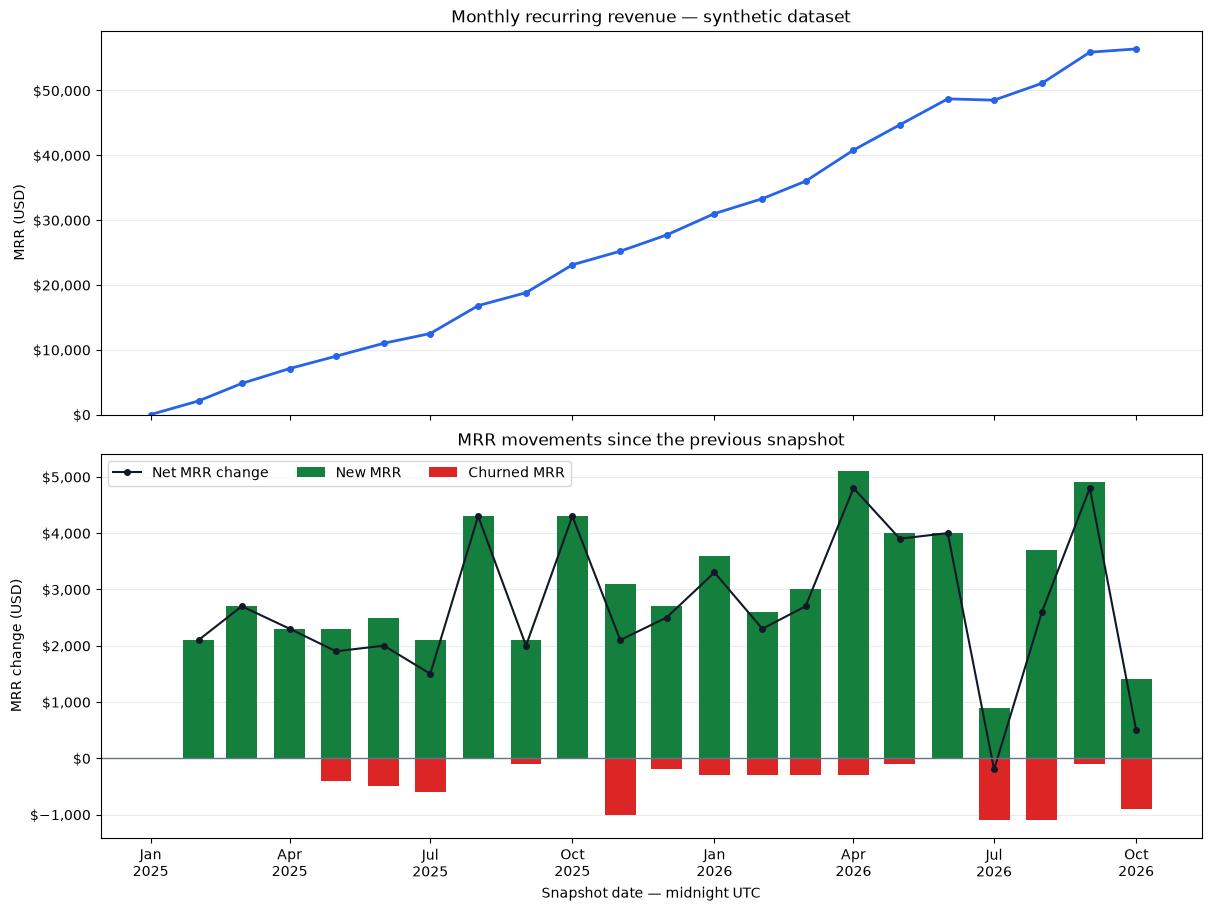

In [2]:
from datetime import timedelta, timezone

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True,
    constrained_layout=True,
)

# Chart 1: MRR at each reporting instant
axes[0].plot(
    mrr["snapshot_date"],
    mrr["total_mrr_usd"].astype(float),
    color="#2563eb",
    linewidth=2,
    marker="o",
    markersize=4,
)

axes[0].set_title("Monthly recurring revenue — synthetic dataset")
axes[0].set_ylabel("MRR (USD)")
axes[0].set_ylim(bottom=0)

# Chart 2: Changes since the previous snapshot
axes[1].bar(
    movements["snapshot_date"],
    movements["new_mrr_usd"].astype(float),
    width=timedelta(days=20),
    color="#15803d",
    label="New MRR",
)

axes[1].bar(
    movements["snapshot_date"],
    -movements["churned_mrr_usd"].astype(float),
    width=timedelta(days=20),
    color="#dc2626",
    label="Churned MRR",
)

axes[1].plot(
    movements["snapshot_date"],
    movements["net_mrr_change_usd"].astype(float),
    color="#111827",
    linewidth=1.5,
    marker="o",
    markersize=4,
    label="Net MRR change",
)

axes[1].axhline(0, color="#64748b", linewidth=1)
axes[1].set_title("MRR movements since the previous snapshot")
axes[1].set_ylabel("MRR change (USD)")
axes[1].set_xlabel("Snapshot date — midnight UTC")
axes[1].legend(loc="upper left", ncol=3)

for axis in axes:
    axis.yaxis.set_major_formatter(
        StrMethodFormatter("${x:,.0f}")
    )
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)

axes[1].xaxis.set_major_locator(
    mdates.MonthLocator(
        bymonth=[1, 4, 7, 10],
        tz=timezone.utc,
    )
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%b\n%Y", tz=timezone.utc)
)

plt.show()

In [3]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


### Initial findings — synthetic dataset

- At October 1, 2026, the generated population had 216 active accounts
  contributing USD 56,400 in monthly recurring revenue.

- Between June 1 and July 1, 2026, active accounts increased from
  194 to 195, while MRR decreased from USD 48,700 to USD 48,500.

- Four new subscriptions added USD 900 in MRR, while three
  cancellations removed USD 1,100 in MRR. This explains the
  USD 200 decline despite an increase in active account count.

- All 21 monthly intervals reconciled:
  opening MRR + new MRR − churned MRR = closing MRR.

### Interpretation limits

These results describe simulated data with fixed subscription prices.
The current movement model covers new subscriptions and churn.

Generated signup dates end before September 1, 2026. Therefore,
the final interval's acquisition activity is affected by the simulation
window and should not be interpreted as evidence of a real business
slowdown.

In [4]:
query = """
WITH report_settings AS (
    SELECT
        TIMESTAMPTZ '2026-10-01 00:00:00+00' AS as_of
),

plan_totals AS (
    SELECT
        s.plan_name,
        COUNT(DISTINCT s.account_id) AS active_accounts,
        SUM(
            s.billing_amount_usd / s.billing_interval_months
        ) AS total_mrr_usd

    FROM subscriptions AS s
    CROSS JOIN report_settings AS r

    WHERE LEFT(s.subscription_id, 4) = 'SYN_'
      AND s.started_at <= r.as_of
      AND (
          s.ended_at IS NULL
          OR s.ended_at > r.as_of
      )

    GROUP BY s.plan_name
)

SELECT
    plan_name,
    active_accounts,
    ROUND(total_mrr_usd, 2) AS total_mrr_usd,

    ROUND(
        100.0 * total_mrr_usd
        / NULLIF(SUM(total_mrr_usd) OVER (), 0),
        2
    ) AS mrr_share_pct

FROM plan_totals
ORDER BY total_mrr_usd DESC;
"""

with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    connect_timeout=5,
) as connection:
    plan_summary = load_dataframe(connection, query)

plan_summary

,plan_name,active_accounts,total_mrr_usd,mrr_share_pct
0,Enterprise,72,36000.00,63.83
1,Growth,60,12000.00,21.28
2,Starter,84,8400.00,14.89


In [5]:
july_query = """
WITH report_settings AS (
    SELECT
        TIMESTAMPTZ '2026-06-01 00:00:00+00' AS period_start,
        TIMESTAMPTZ '2026-07-01 00:00:00+00' AS period_end
),

subscription_events AS (
    SELECT
        plan_name,
        started_at AS event_at,
        'new' AS event_type,
        billing_amount_usd / billing_interval_months AS mrr_usd
    FROM subscriptions
    WHERE LEFT(subscription_id, 4) = 'SYN_'

    UNION ALL

    SELECT
        plan_name,
        ended_at AS event_at,
        'churn' AS event_type,
        billing_amount_usd / billing_interval_months AS mrr_usd
    FROM subscriptions
    WHERE LEFT(subscription_id, 4) = 'SYN_'
      AND ended_at IS NOT NULL
)

SELECT
    e.plan_name,

    COUNT(*) FILTER (
        WHERE e.event_type = 'new'
    ) AS new_subscriptions,

    ROUND(
        COALESCE(
            SUM(e.mrr_usd) FILTER (
                WHERE e.event_type = 'new'
            ),
            0
        ),
        2
    ) AS new_mrr_usd,

    COUNT(*) FILTER (
        WHERE e.event_type = 'churn'
    ) AS churned_subscriptions,

    ROUND(
        COALESCE(
            SUM(e.mrr_usd) FILTER (
                WHERE e.event_type = 'churn'
            ),
            0
        ),
        2
    ) AS churned_mrr_usd,

    ROUND(
        SUM(
            CASE
                WHEN e.event_type = 'new' THEN e.mrr_usd
                ELSE -e.mrr_usd
            END
        ),
        2
    ) AS net_mrr_change_usd

FROM subscription_events AS e
CROSS JOIN report_settings AS r

WHERE e.event_at > r.period_start
  AND e.event_at <= r.period_end

GROUP BY e.plan_name
ORDER BY net_mrr_change_usd;
"""

with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    connect_timeout=5,
) as connection:
    july_plan_movements = load_dataframe(
        connection,
        july_query,
    )

july_plan_movements

,plan_name,new_subscriptions,new_mrr_usd,churned_subscriptions,churned_mrr_usd,net_mrr_change_usd
0,Enterprise,1,500.00,2,1000.00,-500.00
1,Starter,2,200.00,1,100.00,100.00
2,Growth,1,200.00,0,0.00,200.00


In [6]:
churn_query = """
WITH report_settings AS (
    SELECT
        TIMESTAMPTZ '2026-06-01 00:00:00+00' AS period_start,
        TIMESTAMPTZ '2026-07-01 00:00:00+00' AS period_end
)

SELECT
    s.plan_name,

    COUNT(*) AS opening_subscriptions,

    COUNT(*) FILTER (
        WHERE s.ended_at <= r.period_end
    ) AS churned_subscriptions,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE s.ended_at <= r.period_end
        )
        / NULLIF(COUNT(*), 0),
        2
    ) AS subscription_churn_pct

FROM subscriptions AS s
CROSS JOIN report_settings AS r

WHERE LEFT(s.subscription_id, 4) = 'SYN_'
  AND s.started_at <= r.period_start
  AND (
      s.ended_at IS NULL
      OR s.ended_at > r.period_start
  )

GROUP BY s.plan_name
ORDER BY subscription_churn_pct DESC;
"""

with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    connect_timeout=5,
) as connection:
    churn_by_plan = load_dataframe(connection, churn_query)

churn_by_plan

,plan_name,opening_subscriptions,churned_subscriptions,subscription_churn_pct
0,Enterprise,60,2,3.33
1,Starter,81,1,1.23
2,Growth,53,0,0.00


In [7]:
import pandas as pd
import psycopg

query = """
SELECT *
FROM monthly_plan_churn
ORDER BY snapshot_date, plan_name;
"""

with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    connect_timeout=5,
) as connection:
    with connection.cursor() as cursor:
        cursor.execute(query)
        columns = [column.name for column in cursor.description]
        monthly_plan_churn = pd.DataFrame.from_records(
            cursor.fetchall(),
            columns=columns,
        )

for column in ["period_start_date", "snapshot_date"]:
    monthly_plan_churn[column] = pd.to_datetime(
        monthly_plan_churn[column],
        utc=True,
    )

print("Rows loaded:", len(monthly_plan_churn))
print("Reporting periods:", monthly_plan_churn["snapshot_date"].nunique())
print("Plans:", monthly_plan_churn["plan_name"].nunique())

monthly_plan_churn.tail(9)

Rows loaded: 63
Reporting periods: 21
Plans: 3


,period_start_date,snapshot_date,plan_name,opening_subscriptions,churned_subscriptions,subscription_churn_pct
54,2026-07-01 00:00:00+00:00,2026-08-01 00:00:00+00:00,Enterprise,59,1,1.69
55,2026-07-01 00:00:00+00:00,2026-08-01 00:00:00+00:00,Growth,54,2,3.70
56,2026-07-01 00:00:00+00:00,2026-08-01 00:00:00+00:00,Starter,82,2,2.44
57,2026-08-01 00:00:00+00:00,2026-09-01 00:00:00+00:00,Enterprise,63,0,0.00
58,2026-08-01 00:00:00+00:00,2026-09-01 00:00:00+00:00,Growth,56,0,0.00
59,2026-08-01 00:00:00+00:00,2026-09-01 00:00:00+00:00,Starter,84,1,1.19
60,2026-09-01 00:00:00+00:00,2026-10-01 00:00:00+00:00,Enterprise,71,1,1.41
61,2026-09-01 00:00:00+00:00,2026-10-01 00:00:00+00:00,Growth,60,1,1.67
62,2026-09-01 00:00:00+00:00,2026-10-01 00:00:00+00:00,Starter,84,2,2.38


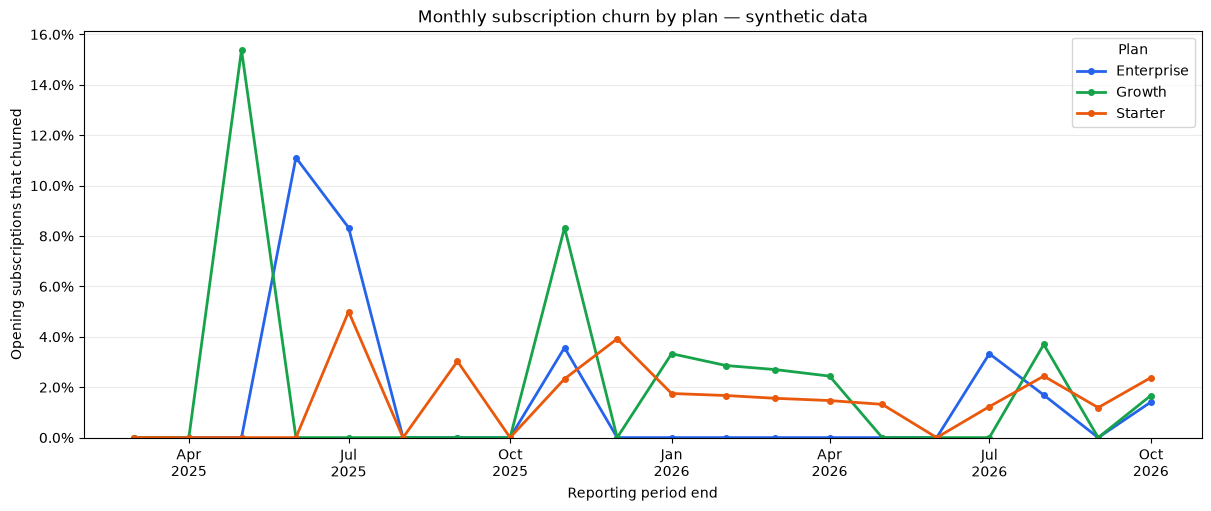

In [8]:
from datetime import timezone

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

churn_trend = (
    monthly_plan_churn.pivot(
        index="snapshot_date",
        columns="plan_name",
        values="subscription_churn_pct",
    )
    .sort_index()
    .astype(float)
)

plan_colors = {
    "Enterprise": "#2563eb",
    "Growth": "#16a34a",
    "Starter": "#ea580c",
}

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)

for plan, color in plan_colors.items():
    ax.plot(
        churn_trend.index,
        churn_trend[plan],
        label=plan,
        color=color,
        marker="o",
        markersize=4,
        linewidth=2,
    )

ax.set_title("Monthly subscription churn by plan — synthetic data")
ax.set_xlabel("Reporting period end")
ax.set_ylabel("Opening subscriptions that churned")
ax.set_ylim(bottom=0)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.xaxis.set_major_locator(
    mdates.MonthLocator(bymonth=[1, 4, 7, 10], tz=timezone.utc)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b\n%Y", tz=timezone.utc)
)

ax.grid(axis="y", alpha=0.25)
ax.legend(title="Plan")

plt.show()

In [9]:
from IPython.display import display

# Inspect the subscription counts behind the highest monthly rates.
largest_spikes = (
    monthly_plan_churn.sort_values(
        "subscription_churn_pct",
        ascending=False,
        na_position="last",
    )
    .head(6)
    [
        [
            "period_start_date",
            "snapshot_date",
            "plan_name",
            "opening_subscriptions",
            "churned_subscriptions",
            "subscription_churn_pct",
        ]
    ]
)

# Pool the counts across reporting periods for each plan.
plan_churn_summary = (
    monthly_plan_churn.groupby("plan_name")
    .agg(
        opening_subscription_periods=("opening_subscriptions", "sum"),
        churn_events=("churned_subscriptions", "sum"),
    )
    .reset_index()
)

denominator = plan_churn_summary["opening_subscription_periods"]

plan_churn_summary["pooled_monthly_churn_pct"] = (
    100
    * plan_churn_summary["churn_events"]
    / denominator.where(denominator > 0)
).round(2)

plan_churn_summary = plan_churn_summary.sort_values(
    "pooled_monthly_churn_pct",
    ascending=False,
)

print("Largest monthly churn rates and their underlying counts:")
display(largest_spikes)

print("Churn summary across all reporting periods:")
display(plan_churn_summary)

Largest monthly churn rates and their underlying counts:


,period_start_date,snapshot_date,plan_name,opening_subscriptions,churned_subscriptions,subscription_churn_pct
10,2025-04-01 00:00:00+00:00,2025-05-01 00:00:00+00:00,Growth,13,2,15.38
12,2025-05-01 00:00:00+00:00,2025-06-01 00:00:00+00:00,Enterprise,9,1,11.11
15,2025-06-01 00:00:00+00:00,2025-07-01 00:00:00+00:00,Enterprise,12,1,8.33
28,2025-10-01 00:00:00+00:00,2025-11-01 00:00:00+00:00,Growth,24,2,8.33
17,2025-06-01 00:00:00+00:00,2025-07-01 00:00:00+00:00,Starter,20,1,5.00
32,2025-11-01 00:00:00+00:00,2025-12-01 00:00:00+00:00,Starter,51,2,3.92


Churn summary across all reporting periods:


,plan_name,opening_subscription_periods,churn_events,pooled_monthly_churn_pct
1,Growth,618,11,1.78
2,Starter,995,16,1.61
0,Enterprise,650,7,1.08


### Subscription churn findings — synthetic data

Across 21 reporting periods, pooled monthly subscription churn was:

| Plan | Churn events | Opening subscription-periods | Pooled monthly churn |
|---|---:|---:|---:|
| Growth | 11 | 618 | 1.78% |
| Starter | 16 | 995 | 1.61% |
| Enterprise | 7 | 650 | 1.08% |

The pooled rate equals total churn events divided by total opening
subscription counts across periods, multiplied by 100. A subscription
can appear in several periods, so this is not cumulative customer churn.

Monthly rankings varied. Enterprise had the highest churn rate between
June 1 and July 1, 2026, but the lowest pooled rate across the full history.

Small opening populations amplified early spikes:

- Growth's 15.38% rate between April 1 and May 1, 2025 represented
  2 churns among 13 opening subscriptions.
- Enterprise's 11.11% rate between May 1 and June 1, 2025 represented
  1 churn among 9 opening subscriptions.

These are descriptive findings from synthetic data. They do not establish
that plan choice causes churn. Comparing subscription tenure and billing
interval would help investigate the differences.

,aging_bucket,unpaid_invoice_count,outstanding_balance_usd,share_of_outstanding_pct
0,Not overdue,36,8300.00,8.48
1,1-30 days,26,12420.00,12.68
2,31-60 days,27,6300.00,6.43
3,61-90 days,27,6200.00,6.33
4,91+ days,211,64700.00,66.07


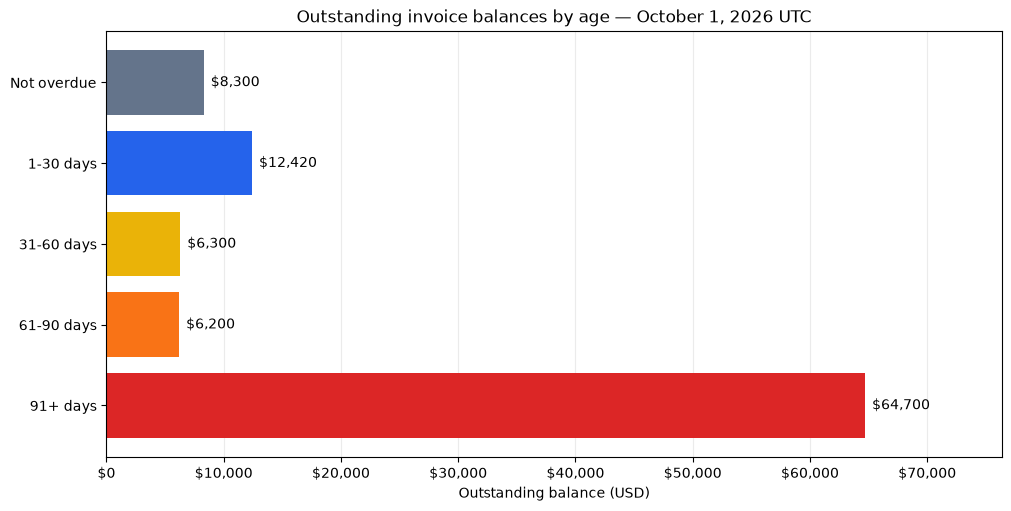

In [10]:
import pandas as pd
import psycopg
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display

aging_query = """
SELECT
    aging_bucket,
    COUNT(*) AS unpaid_invoice_count,
    SUM(outstanding_balance_usd) AS outstanding_balance_usd
FROM invoice_aging_snapshot
WHERE outstanding_balance_usd > 0
GROUP BY aging_bucket
ORDER BY CASE aging_bucket
    WHEN 'Not overdue' THEN 1
    WHEN '1-30 days' THEN 2
    WHEN '31-60 days' THEN 3
    WHEN '61-90 days' THEN 4
    ELSE 5
END;
"""

with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    connect_timeout=5,
) as connection:
    with connection.cursor() as cursor:
        cursor.execute(aging_query)
        columns = [column.name for column in cursor.description]
        aging_summary = pd.DataFrame.from_records(
            cursor.fetchall(),
            columns=columns,
        )

# Use float values for percentages and plotting.
# Keep the original decimal currency column unchanged.
balances_for_plot = aging_summary["outstanding_balance_usd"].astype(float)

aging_summary["share_of_outstanding_pct"] = (
    100 * balances_for_plot / balances_for_plot.sum()
).round(2)

display(aging_summary)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

bars = ax.barh(
    aging_summary["aging_bucket"],
    balances_for_plot,
    color=["#64748b", "#2563eb", "#eab308", "#f97316", "#dc2626"],
)

ax.invert_yaxis()
ax.bar_label(
    bars,
    labels=[f"${value:,.0f}" for value in balances_for_plot],
    padding=5,
)

ax.set_title("Outstanding invoice balances by age — October 1, 2026 UTC")
ax.set_xlabel("Outstanding balance (USD)")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.margins(x=0.18)

plt.show()

### Invoice aging findings — synthetic project dataset

At the October 1, 2026 UTC cutoff, 327 invoices had outstanding
balances totaling USD 97,920.

All monetary amounts in the table are in USD.

| Invoice age | Invoices with balance | Outstanding balance |
|---|---:|---:|
| Not overdue | 36 | 8,300 |
| 1–30 days overdue | 26 | 12,420 |
| 31–60 days overdue | 27 | 6,300 |
| 61–90 days overdue | 27 | 6,200 |
| 91+ days overdue | 211 | 64,700 |

Of the outstanding balance, USD 89,620 was overdue across 291 invoices.
The remaining USD 8,300 was not overdue.

The 91+ day bucket held USD 64,700, or 66.07% of outstanding dollars.
Older invoices therefore held the largest concentration of unpaid balances.

Outstanding balances are not confirmed revenue losses. Aging alone does
not establish collectibility or explain why payment is late.

This report includes synthetic records and the two original example
invoices. It counts invoices issued and successful payments completed
before the fixed reporting cutoff.

Accounts with outstanding balances: 154
Total overdue balance: $89,620.00
Top 10 overdue balance: $31,200.00
Top 10 share of overdue dollars: 34.81%


,account_id,account_name,overdue_invoice_count,overdue_balance_usd,balance_91_plus_usd,oldest_unpaid_days_past_due
12,SYN_ACC0243,Synthetic Account 0243,1,6000.00,6000.00,163
119,SYN_ACC0052,Synthetic Account 0052,1,6000.00,0,17
48,SYN_ACC0093,Synthetic Account 0093,2,4800.00,4800.00,577
131,SYN_ACC0175,Synthetic Account 0175,1,3600.00,3600.00,455
0,SYN_ACC0099,Synthetic Account 0099,1,2400.00,2400.00,222
136,SYN_ACC0049,Synthetic Account 0049,5,2100.00,2100.00,537
10,SYN_ACC0039,Synthetic Account 0039,4,1800.00,1300.00,390
135,SYN_ACC0045,Synthetic Account 0045,3,1500.00,1000.00,360
60,SYN_ACC0168,Synthetic Account 0168,3,1500.00,1000.00,357
52,SYN_ACC0091,Synthetic Account 0091,3,1500.00,500.00,356


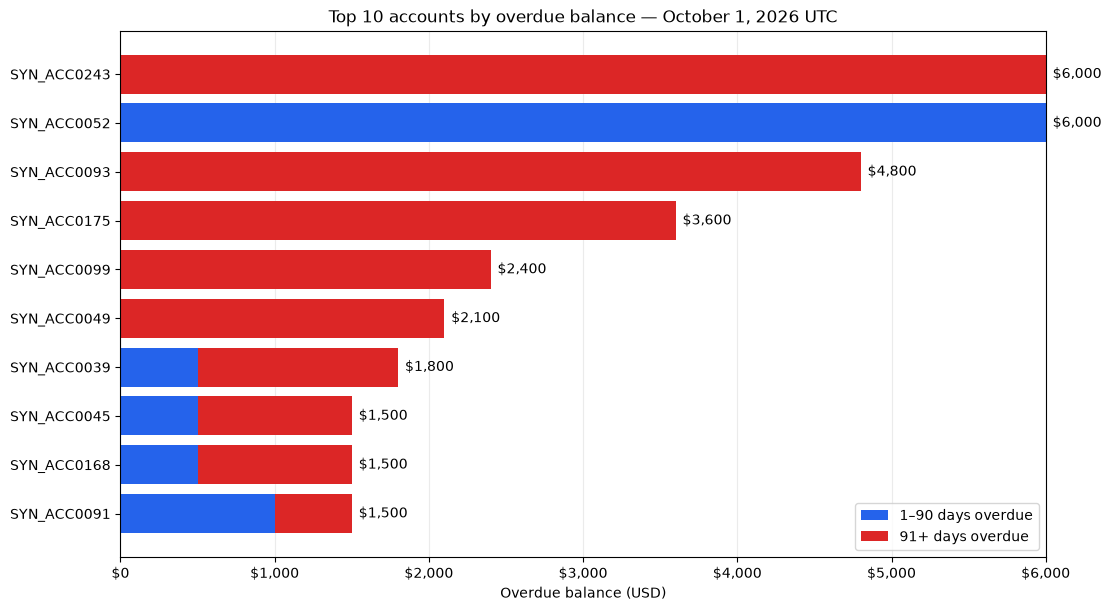

In [11]:
import pandas as pd
import psycopg
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display

query = """
SELECT *
FROM account_collection_summary;
"""

with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    connect_timeout=5,
) as connection:
    with connection.cursor() as cursor:
        cursor.execute(query)
        columns = [column.name for column in cursor.description]
        account_collections = pd.DataFrame.from_records(
            cursor.fetchall(),
            columns=columns,
        )

top_accounts = (
    account_collections.loc[
        account_collections["overdue_balance_usd"] > 0
    ]
    .sort_values(
        [
            "overdue_balance_usd",
            "oldest_unpaid_days_past_due",
            "account_id",
        ],
        ascending=[False, False, True],
    )
    .head(10)
)

total_overdue = account_collections["overdue_balance_usd"].sum()
top_accounts_overdue = top_accounts["overdue_balance_usd"].sum()

top_accounts_share = (
    100 * top_accounts_overdue / total_overdue
    if total_overdue > 0
    else 0
)

print(f"Accounts with outstanding balances: {len(account_collections)}")
print(f"Total overdue balance: ${total_overdue:,.2f}")
print(f"Top 10 overdue balance: ${top_accounts_overdue:,.2f}")
print(f"Top 10 share of overdue dollars: {top_accounts_share:.2f}%")

display(
    top_accounts[
        [
            "account_id",
            "account_name",
            "overdue_invoice_count",
            "overdue_balance_usd",
            "balance_91_plus_usd",
            "oldest_unpaid_days_past_due",
        ]
    ]
)

# Separate overdue balances into two non-overlapping age groups.
recent_overdue = (
    top_accounts["overdue_balance_usd"]
    - top_accounts["balance_91_plus_usd"]
).astype(float)

older_overdue = top_accounts["balance_91_plus_usd"].astype(float)

fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)

ax.barh(
    top_accounts["account_id"],
    recent_overdue,
    label="1–90 days overdue",
    color="#2563eb",
)

older_bars = ax.barh(
    top_accounts["account_id"],
    older_overdue,
    left=recent_overdue,
    label="91+ days overdue",
    color="#dc2626",
)

ax.bar_label(
    older_bars,
    labels=[
        f"${value:,.0f}"
        for value in top_accounts["overdue_balance_usd"]
    ],
    padding=5,
)

ax.invert_yaxis()
ax.set_title("Top 10 accounts by overdue balance — October 1, 2026 UTC")
ax.set_xlabel("Overdue balance (USD)")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.margins(x=0.20)
ax.legend()

plt.show()

### Account-level collection review — October 1, 2026 UTC

There were 154 accounts with outstanding invoice balances.

The ten accounts with the largest overdue balances held USD 31,200,
representing 34.81% of the total USD 89,620 overdue balance.

Balance size and age provide different information:

- SYN_ACC0243 owed USD 6,000, entirely at least 91 days overdue.
  Its oldest unpaid invoice was 163 days overdue.
- SYN_ACC0052 also owed USD 6,000, but its unpaid invoice was
  only 17 days overdue.
- SYN_ACC0093 owed USD 4,800, entirely at least 91 days overdue.
  Its oldest unpaid invoice was 577 days overdue.

Accounts are ranked by overdue dollars, with invoice age breaking ties.
The list provides a starting point for reviewing payment histories
and deciding appropriate follow-up.

Balances and ages alone do not explain nonpayment or establish
recoverable amounts.

These findings use the synthetic project dataset and original example
records. No collection actions have been taken.

In [12]:
import pandas as pd
import psycopg
from IPython.display import display

query = """
SELECT
    payment_activity_category,
    COUNT(*) AS overdue_invoice_count,
    SUM(outstanding_balance_usd) AS overdue_balance_usd,
    COALESCE(
        SUM(outstanding_balance_usd) FILTER (
            WHERE days_past_due >= 91
        ),
        0
    ) AS balance_91_plus_usd
FROM overdue_payment_diagnostics
GROUP BY payment_activity_category
ORDER BY overdue_balance_usd DESC;
"""

with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    connect_timeout=5,
) as connection:
    with connection.cursor() as cursor:
        cursor.execute(query)
        columns = [column.name for column in cursor.description]
        payment_activity_summary = pd.DataFrame.from_records(
            cursor.fetchall(),
            columns=columns,
        )

balances = payment_activity_summary["overdue_balance_usd"].astype(float)

payment_activity_summary["share_of_overdue_pct"] = (
    100 * balances / balances.sum()
).round(2)

display(payment_activity_summary)

,payment_activity_category,overdue_invoice_count,overdue_balance_usd,balance_91_plus_usd,share_of_overdue_pct
0,Failed attempts only,142,41400.00,30600.00,46.20
1,No completed attempts,88,34900.00,22700.00,38.94
2,Partially paid,61,13320.00,11400.00,14.86


### Payment activity behind overdue invoices

At the October 1, 2026 UTC cutoff, all 291 overdue invoices were
classified without duplicating invoice balances.

All monetary amounts below are in USD.

| Payment activity | Invoices | Overdue balance | Share of overdue dollars |
|---|---:|---:|---:|
| Failed attempts only | 142 | 41,400 | 46.20% |
| No completed attempts | 88 | 34,900 | 38.94% |
| Partially paid | 61 | 13,320 | 14.86% |
| Total | 291 | 89,620 | 100.00% |

Failed attempts accounted for the largest share of overdue dollars.
A substantial balance also had no completed attempts recorded.

Suggested investigations:

- Failed attempts only: examine recorded failure reasons and retry
  history before deciding on further collection steps.
- No completed attempts: verify whether collection was initiated,
  whether any attempt remains pending, and whether records are complete.
- Partially paid: review successful payments and the remaining invoice
  balance to determine the appropriate follow-up.

Balances at least 91 days overdue were USD 30,600 for failed attempts
only, USD 22,700 for no completed attempts, and USD 11,400 for partially
paid invoices.

These categories describe recorded payment activity. They do not establish
the cause of nonpayment or predict recoverable cash. No completed attempt
does not necessarily mean no attempt was initiated.

The analysis uses the synthetic project dataset and original example
records. No payment retries or customer communications were performed.

## Subscription cohort retention

This analysis reads the tested dbt view
`analytics.fct_monthly_cohort_retention`.

Each row represents subscriptions grouped by their UTC start month.
Month 1 is the first monthly checkpoint after that start month,
rather than an exact subscription anniversary.

Retention measures the percentage of the original cohort still subscribed,
regardless of payment status.

Compare cohorts within the same month-number column.
Gray cells represent checkpoints that have not yet been observed;
they do not mean zero retention.

In [13]:
import pandas as pd
import psycopg
import matplotlib.pyplot as plt

retention_query = """
SELECT
    cohort_month,
    snapshot_date,
    month_number,
    cohort_subscriptions,
    retained_subscriptions,
    retention_pct
FROM analytics.fct_monthly_cohort_retention
ORDER BY cohort_month, month_number;
"""

with psycopg.connect(
    host="localhost",
    port=5432,
    dbname="saas_analytics",
    user="chandrahassai",
) as retention_connection:
    with retention_connection.cursor() as retention_cursor:
        retention_cursor.execute(retention_query)

        retention_records = retention_cursor.fetchall()
        retention_columns = [
            column.name for column in retention_cursor.description
        ]

cohort_retention_df = pd.DataFrame(
    retention_records,
    columns=retention_columns,
)

cohort_retention_df["cohort_month"] = pd.to_datetime(
    cohort_retention_df["cohort_month"]
)

cohort_retention_df["snapshot_date"] = pd.to_datetime(
    cohort_retention_df["snapshot_date"]
)

cohort_retention_df["retention_pct"] = (
    cohort_retention_df["retention_pct"].astype(float)
)

print(f"Loaded {len(cohort_retention_df)} cohort checkpoints.")

cohort_retention_df.head()

Loaded 231 cohort checkpoints.


,cohort_month,snapshot_date,month_number,cohort_subscriptions,retained_subscriptions,retention_pct
0,2025-01-01,2025-02-01,1,8,8,100.0
1,2025-01-01,2025-03-01,2,8,8,100.0
2,2025-01-01,2025-04-01,3,8,8,100.0
3,2025-01-01,2025-05-01,4,8,8,100.0
4,2025-01-01,2025-06-01,5,8,7,87.5


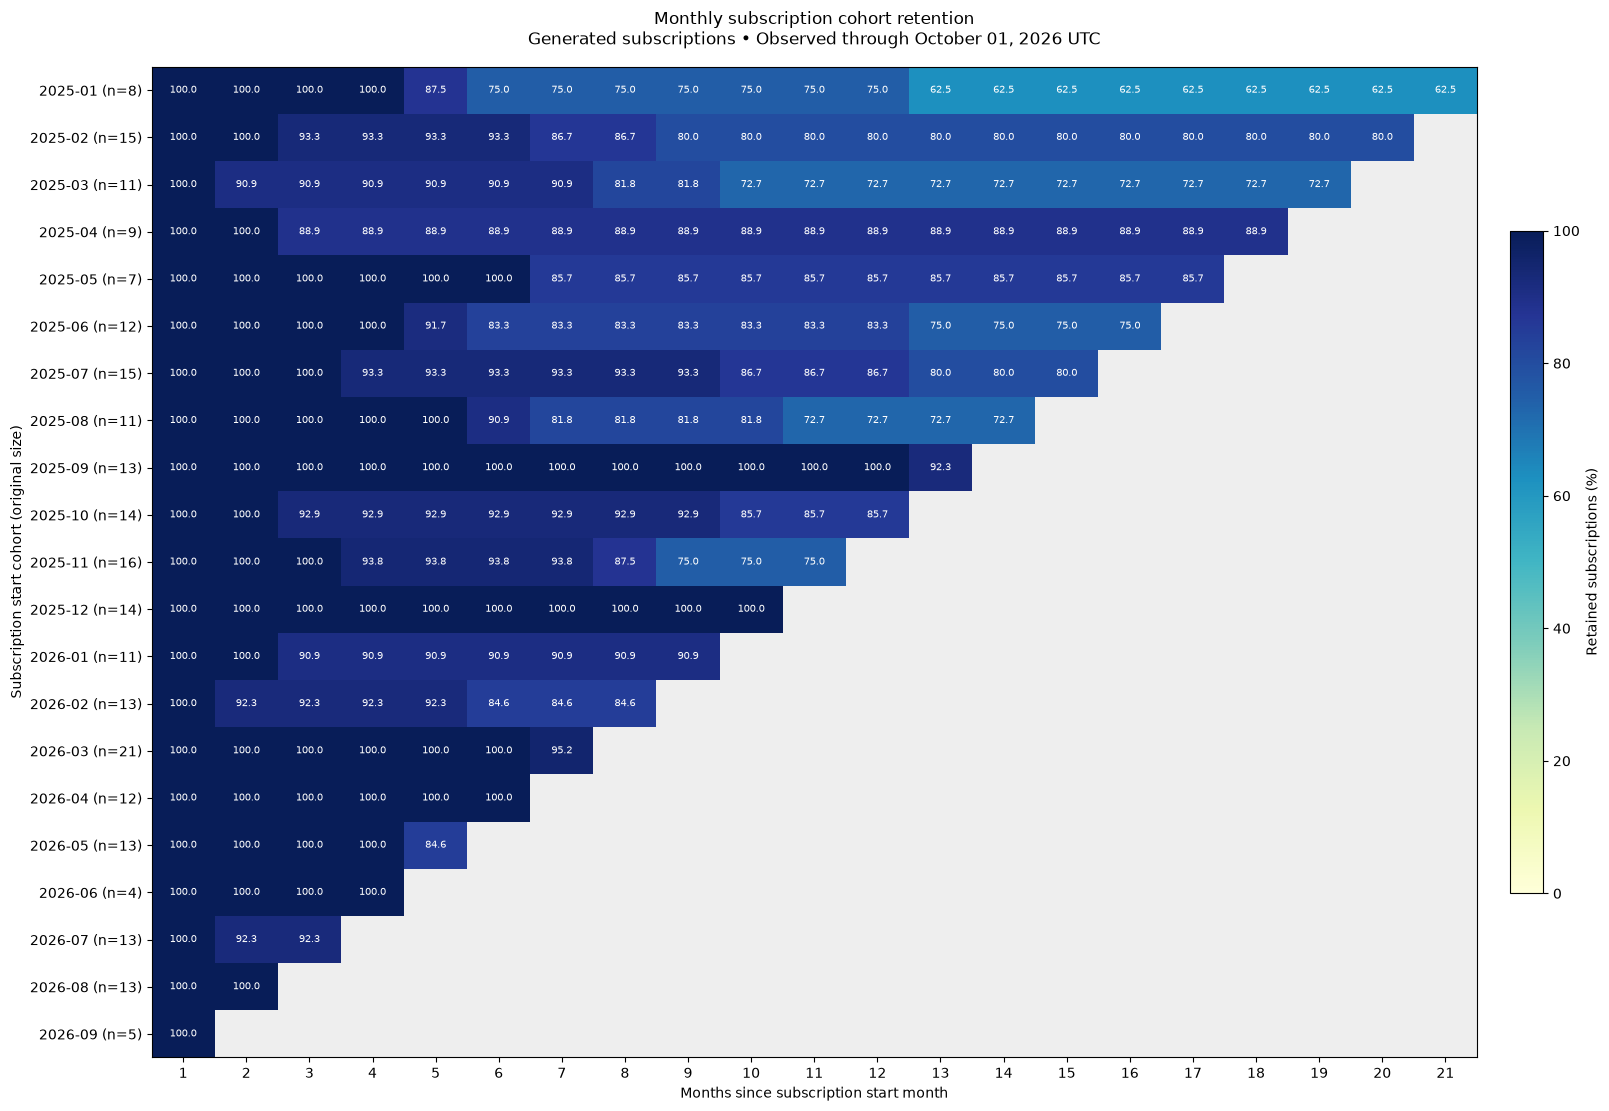

In [14]:
retention_matrix = (
    cohort_retention_df.pivot(
        index="cohort_month",
        columns="month_number",
        values="retention_pct",
    )
    .sort_index()
    .sort_index(axis=1)
)

retention_cohort_sizes = (
    cohort_retention_df.groupby("cohort_month")[
        "cohort_subscriptions"
    ].first()
)

retention_row_labels = [
    f"{cohort:%Y-%m} (n={int(retention_cohort_sizes.loc[cohort])})"
    for cohort in retention_matrix.index
]

retention_cutoff_label = (
    cohort_retention_df["snapshot_date"]
    .max()
    .strftime("%B %d, %Y")
)

retention_values = retention_matrix.to_numpy(dtype=float)

retention_cmap = plt.get_cmap("YlGnBu").copy()
retention_cmap.set_bad("#eeeeee")

retention_fig, retention_ax = plt.subplots(
    figsize=(16, 11),
    layout="constrained",
)

retention_image = retention_ax.imshow(
    retention_values,
    cmap=retention_cmap,
    vmin=0,
    vmax=100,
    aspect="auto",
    interpolation="nearest",
)

retention_ax.set_xticks(
    range(len(retention_matrix.columns)),
    labels=retention_matrix.columns,
)

retention_ax.set_yticks(
    range(len(retention_matrix.index)),
    labels=retention_row_labels,
)

retention_ax.set_xlabel("Months since subscription start month")
retention_ax.set_ylabel("Subscription start cohort (original size)")

retention_ax.set_title(
    "Monthly subscription cohort retention\n"
    f"Generated subscriptions • Observed through {retention_cutoff_label} UTC",
    pad=16,
)

for row_number in range(retention_values.shape[0]):
    for column_number in range(retention_values.shape[1]):
        value = retention_values[row_number, column_number]

        if pd.notna(value):
            retention_ax.text(
                column_number,
                row_number,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if value >= 60 else "black",
            )

retention_colorbar = retention_fig.colorbar(
    retention_image,
    ax=retention_ax,
    fraction=0.025,
    pad=0.025,
)

retention_colorbar.set_label("Retained subscriptions (%)")

plt.show()

### Retention findings and interpretation

The analysis covers 21 subscription start-month cohorts and 231 observed
cohort checkpoints.

The January 2025 cohort retained all eight subscriptions at month 1,
six at months 6 and 12, and five at month 21. Its retention therefore
declined from 100.00% to 62.50% over the observed period.

Compare cohorts within the same month-number column. The last visible
cell in each row represents a different cohort age, so those cells
should not be used directly to rank cohort performance.

Cohorts are small. For the January cohort of eight subscriptions,
one cancellation changes retention by 12.5 percentage points.

These results describe synthetic subscription histories. They do not
establish why customers churned or demonstrate the effect of a business
intervention.